# Evo2 Zero-shot Validation on TTN ClinVar Dataset

This notebook validates Evo2 pathogenicity predictions on TTN ClinVar variants and generates:
- Confusion Matrix (TP/TN/FP/FN)
- ROC Curve + AUROC + best threshold (Youden's J)
- Delta Score distribution (KDE + Violin + Mann-Whitney p-value)
- ClinVar labels vs Evo2 predictions pie charts

In [ ]:
# 本 notebook 在 research/ 裡；切回 repo 根目錄，讓相對路徑與 import config / utils 照舊可用
import os, sys
from pathlib import Path
if Path.cwd().name == "research":
    os.chdir(Path.cwd().parent)
for _p in (Path.cwd(), Path.cwd() / "research"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

In [1]:
# !pip install evo2 biopython pandas numpy matplotlib seaborn scipy scikit-learn

In [2]:
from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

os.environ['TRITON_PTXAS_PATH'] = '/usr/local/cuda/bin/ptxas'

from scipy.stats import mannwhitneyu
from sklearn.metrics import confusion_matrix, roc_curve, auc
from config import PATHOGENIC_THRESHOLD
from utils.evo2_predictor import Evo2Predictor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 6)

In [3]:
CSV_PATH = Path('/home/ryan910702/ttn-agent/research/data/clinvar_latest.csv')
FASTA_PATH = Path('/home/ryan910702/ttn-agent/data/sequence.fasta')
assert CSV_PATH.exists(), f'CSV not found: {CSV_PATH}'
assert FASTA_PATH.exists(), f'FASTA not found: {FASTA_PATH}'

df = pd.read_csv(CSV_PATH)
print(f'Total rows: {len(df)}')
print('Columns:', list(df.columns))
df[['chr', 'position', 'ref', 'alt', 'Germline classification']].head()

Total rows: 4990
Columns: ['Name', 'Gene(s)', 'Protein change', 'Condition(s)', 'Accession', 'GRCh37Chromosome', 'GRCh37Location', 'GRCh38Chromosome', 'GRCh38Location', 'VariationID', 'AlleleID(s)', 'dbSNP ID', 'Canonical SPDI', 'Variant type', 'Molecular consequence', 'Germline classification', 'Germline date last evaluated', 'Germline review status', 'Somatic clinical impact', 'Somatic clinical impact date last evaluated', 'Somatic clinical impact review status', 'Oncogenicity classification', 'Oncogenicity date last evaluated', 'Oncogenicity review status', 'Unnamed: 24', 'Unnamed: 25', 'chr', 'position', 'ref', 'alt', 'ground trruth', 'cardiac', 'muscular']


,chr,position,ref,alt,Germline classification
0,2,178525940,T,C,Benign
1,2,178526348,G,T,Benign/Likely benign
2,2,178527023,C,A,Likely benign
3,2,178527036,G,A,Likely benign
4,2,178527093,T,C,Likely benign


In [4]:
def normalize_clinvar_label(text: str) -> str:
    t = str(text).lower()
    if 'pathogenic' in t and 'benign' not in t:
        return 'pathogenic'
    if 'benign' in t:
        return 'benign'
    return 'uncertain'


df['clinvar_label'] = df['Germline classification'].map(normalize_clinvar_label)
df['position'] = pd.to_numeric(df['position'], errors='coerce').astype('Int64')
df = df.dropna(subset=['position', 'ref', 'alt', 'clinvar_label']).copy()
df['position'] = df['position'].astype(int)

print(df['clinvar_label'].value_counts())

clinvar_label
benign        4357
pathogenic     633
Name: count, dtype: int64


In [5]:
CHECKPOINT_PATH = Path('/home/ryan910702/ttn-agent/outputs/evo2_scoring_checkpoint.csv')
BATCH_SIZE = 50  # save every N variants
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
predictor = Evo2Predictor()
predictor._load_model()
predictor._load_reference_sequence()
if CHECKPOINT_PATH.exists():
    done_df = pd.read_csv(CHECKPOINT_PATH)
    done_keys = set(zip(done_df['chr'].astype(str), done_df['position'].astype(int),
                        done_df['ref'].astype(str), done_df['alt'].astype(str)))
    print(f'Resuming: {len(done_df)} variants already scored, checkpoint loaded.')
    print('Note: leftover rows from a previous CSV are skipped while scoring,')
    print('      but they stay in the checkpoint file until evaluation filters them.')
else:
    done_df = pd.DataFrame()
    done_keys = set()
    print('No checkpoint found, starting from scratch.')

batch = []
saved_count = len(done_df)

for idx, (_, r) in enumerate(df.iterrows()):
    pos = int(r['position'])
    ref = str(r['ref']).upper()
    alt = str(r['alt']).upper()
    key = (str(r['chr']), pos, ref, alt)

    if key in done_keys:
        continue  # already scored

    ref_seq, var_seq = predictor._parse_sequences(pos=pos, ref=ref, alt=alt)
    if ref_seq is None or var_seq is None:
        continue

    ref_score = float(predictor.model.score_sequences([ref_seq])[0])
    var_score = float(predictor.model.score_sequences([var_seq])[0])
    delta_score = var_score - ref_score

    batch.append({
        'chr': str(r['chr']),
        'position': pos,
        'ref': ref,
        'alt': alt,
        'clinvar_label': r['clinvar_label'],
        'germline_classification': r['Germline classification'],
        'ref_score': ref_score,
        'var_score': var_score,
        'delta_score': delta_score,
        'pred_by_default_threshold': 'pathogenic' if delta_score < PATHOGENIC_THRESHOLD else 'benign'
    })

    if len(batch) >= BATCH_SIZE:
        batch_df = pd.DataFrame(batch)
        done_df = pd.concat([done_df, batch_df], ignore_index=True)
        done_df.to_csv(CHECKPOINT_PATH, index=False)
        saved_count += len(batch)
        print(f'  [{saved_count}/{len(df)}] checkpoint saved ({CHECKPOINT_PATH.name})')
        done_keys.update(zip(batch_df['chr'].astype(str), batch_df['position'].astype(int),
                             batch_df['ref'].astype(str), batch_df['alt'].astype(str)))
        batch = []

# Save any remaining rows
if batch:
    batch_df = pd.DataFrame(batch)
    done_df = pd.concat([done_df, batch_df], ignore_index=True)
    done_df.to_csv(CHECKPOINT_PATH, index=False)
    saved_count += len(batch)
    print(f'  [{saved_count}/{len(df)}] final batch saved.')

# Checkpoint can still contain leftover rows from an earlier CSV.
# Evaluation must use only variants that are in the CURRENT input table.
current_keys = set(zip(
    df['chr'].astype(str),
    df['position'].astype(int),
    df['ref'].astype(str).str.upper(),
    df['alt'].astype(str).str.upper(),
))
result_df = done_df.copy()
result_keys = list(zip(
    result_df['chr'].astype(str),
    result_df['position'].astype(int),
    result_df['ref'].astype(str),
    result_df['alt'].astype(str),
))
n_ckpt = len(result_df)
result_df = result_df.loc[[k in current_keys for k in result_keys]].copy()
if n_ckpt != len(result_df):
    print(
        f'WARNING: checkpoint has {n_ckpt} rows, current CSV has {len(df)} variants.\n'
        f'         Evaluating {len(result_df)} overlapping rows; '
        f'dropped {n_ckpt - len(result_df)} leftover rows from older runs.'
    )
print(f'Usable variants after parsing/scoring: {len(result_df)}')
result_df.head()


[08/18/26 14:13:41] INFO     utils.evo2_predictor - INFO - Loading Evo2 model: evo2_7b_base    ]8;id=6415300;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=6415301;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#39\39]8;;\

                    INFO     httpx - INFO - HTTP Request: GET                                       ]8;id=6415308;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/httpx/_client.py\_client.py]8;;\:]8;id=6415309;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/httpx/_client.py#1025\1025]8;;\
                             https://huggingface.co/api/models/arcinstitute/evo2_7b_base/revision/m                
                             ain "HTTP/1.1 200 OK"                                                                 

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 118987.35it/s]

Found complete file in repo: evo2_7b_base.pt


                    INFO     StripedHyena - INFO - Initializing StripedHyena with config:              ]8;id=6415316;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=6415317;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py#627\627]8;;\
                             {'model_name': 'shc-evo2-7b-8k-2T-v2', 'vocab_size': 512, 'hidden_size':              
                             4096, 'num_filters': 4096, 'hcl_layer_idxs': [2, 6, 9, 13, 16, 20, 23,                
                             27, 30], 'hcm_layer_idxs': [1, 5, 8, 12, 15, 19, 22, 26, 29],                         
                             'hcs_layer_idxs': [0, 4, 7, 11, 14, 18, 21, 25, 28], 'attn_layer_idxs':               
                             [3, 10, 17, 24, 31], 'hcm_filter_length': 128, 'hcl_filter_groups': 4096,             
                             'hcm_filter_groups': 256, 'hcs_filter_groups': 256, 'hcs_filter_length':              
                             7, 'num_layers': 32, 'short_filter_length': 3, 'num_attention_heads': 32,             
                             'short_filter_bias': False, 'mlp_init_method': 'torch.nn.init.zeros_',                
                             'mlp_output_init_method': 'torch.nn.init.zeros_', 'eps': 1e-06,                       
                             'state_size': 16, 'rotary_emb_base': 10000,                                           
                             'make_vocab_size_divisible_by': 8, 'inner_size_multiple_of': 16,                      
                             'inner_mlp_size': 11008, 'log_intermediate_values': False, 'proj_groups':             
                             1, 'hyena_filter_groups': 1, 'column_split_hyena': False, 'column_split':             
                             True, 'interleave': True, 'evo2_style_activations': True,                             
                             'model_parallel_size': 1, 'pipe_parallel_size': 1, 'tie_embeddings':                  
                             True, 'mha_out_proj_bias': True, 'hyena_out_proj_bias': True,                         
                             'hyena_flip_x1x2': False, 'qkv_proj_bias': False,                                     
                             'use_fp8_input_projections': False, 'max_seqlen': 32768,                              
                             'max_batch_size': 1, 'final_norm': True, 'use_flash_attn': True,                      
                             'use_flash_rmsnorm': False, 'use_flash_depthwise': False, 'use_flashfft':             
                             False, 'use_laughing_hyena': False, 'inference_mode': True,                           
                             'tokenizer_type': 'CharLevelTokenizer', 'prefill_style': 'fft',                       
                             'mlp_activation': 'gelu', 'print_activations': False, 'Loader': <class                
                             'yaml.loader.FullLoader'>}                                                            

[08/18/26 14:13:42] INFO     StripedHyena - INFO - Initializing 32 blocks...                           ]8;id=6415323;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py\model.py]8;;\:]8;id=6415324;file:///home/ryan910702/miniconda3/envs/gm4/lib/python3.13/site-packages/vortex/model/model.py#646\646]8;;\

... (81 outputs left out)

Resuming: 7179 variants already scored, checkpoint loaded.
Note: leftover rows from a previous CSV are skipped while scoring,
      but they stay in the checkpoint file until evaluation filters them.


                    ERROR    utils.evo2_predictor - ERROR - Position 178525940 is outside TTN ]8;id=6415766;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py\evo2_predictor.py]8;;\:]8;id=6415767;file:///home/ryan910702/ttn-agent/utils/evo2_predictor.py#101\101]8;;\
                             region (178807423-178525989)                                                          

         Evaluating 4989 overlapping rows; dropped 2190 leftover rows from older runs.
Usable variants after parsing/scoring: 4989


,chr,position,ref,alt,clinvar_label,germline_classification,ref_score,var_score,delta_score,pred_by_default_threshold
0,2,178527121,T,C,pathogenic,Likely pathogenic,-0.947458,-0.956818,-0.009361,pathogenic
1,2,178527148,T,A,pathogenic,Pathogenic/Likely pathogenic,-0.951866,-0.957373,-0.005508,pathogenic
5,2,178527491,C,T,pathogenic,Pathogenic/Likely pathogenic,-0.944176,-0.949875,-0.005699,pathogenic
7,2,178527548,C,T,pathogenic,Pathogenic/Likely pathogenic,-0.926520,-0.936114,-0.009594,pathogenic
9,2,178528273,G,C,pathogenic,Pathogenic/Likely pathogenic,-0.899437,-0.903091,-0.003653,pathogenic


In [6]:
# Restrict to the CURRENT input CSV, then to binary labels.
# Re-run this cell after changing CSV_PATH; you do not need to reload Evo2.
if 'done_df' in globals():
    scored = done_df
elif CHECKPOINT_PATH.exists():
    scored = pd.read_csv(CHECKPOINT_PATH)
else:
    scored = result_df

current_keys = set(zip(
    df['chr'].astype(str),
    df['position'].astype(int),
    df['ref'].astype(str).str.upper(),
    df['alt'].astype(str).str.upper(),
))
scored_keys = list(zip(
    scored['chr'].astype(str),
    scored['position'].astype(int),
    scored['ref'].astype(str),
    scored['alt'].astype(str),
))
result_df = scored.loc[[k in current_keys for k in scored_keys]].copy()
if len(scored) != len(result_df):
    print(
        f'WARNING: checkpoint/scored table has {len(scored)} rows, current CSV has {len(df)} variants.\n'
        f'         Evaluating {len(result_df)} overlapping rows; '
        f'dropped {len(scored) - len(result_df)} leftover rows from older runs.'
    )

eval_df = result_df[result_df['clinvar_label'].isin(['pathogenic', 'benign'])].copy()
print(f'Current CSV rows: {len(df):,}')
print(f'Scored rows used here: {len(result_df):,}')
eval_df['y_true'] = (eval_df['clinvar_label'] == 'pathogenic').astype(int)

# Larger score should indicate more pathogenic for ROC
eval_df['pathogenic_score'] = -eval_df['delta_score']

fpr, tpr, roc_thresholds = roc_curve(eval_df['y_true'], eval_df['pathogenic_score'])
auroc = auc(fpr, tpr)

# Best threshold via Youden's J
j_scores = tpr - fpr
best_idx = int(np.argmax(j_scores))
best_score_threshold = roc_thresholds[best_idx]
best_delta_threshold = -best_score_threshold

eval_df['y_pred_best'] = (eval_df['pathogenic_score'] >= best_score_threshold).astype(int)
eval_df['pred_label_best'] = np.where(eval_df['y_pred_best'] == 1, 'pathogenic', 'benign')

tn, fp, fn, tp = confusion_matrix(eval_df['y_true'], eval_df['y_pred_best']).ravel()

print(f'Binary eval size: {len(eval_df)}')
print(f'AUROC: {auroc:.4f}')
print(f'Best score threshold (on -delta): {best_score_threshold:.6f}')
print(f'Best delta threshold: {best_delta_threshold:.6f}')
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')

         Evaluating 4989 overlapping rows; dropped 2190 leftover rows from older runs.
Current CSV rows: 4,990
Scored rows used here: 4,989
Binary eval size: 4989
AUROC: 0.9928
Best score threshold (on -delta): 0.000662
Best delta threshold: -0.000662
TP=629, TN=4186, FP=170, FN=4


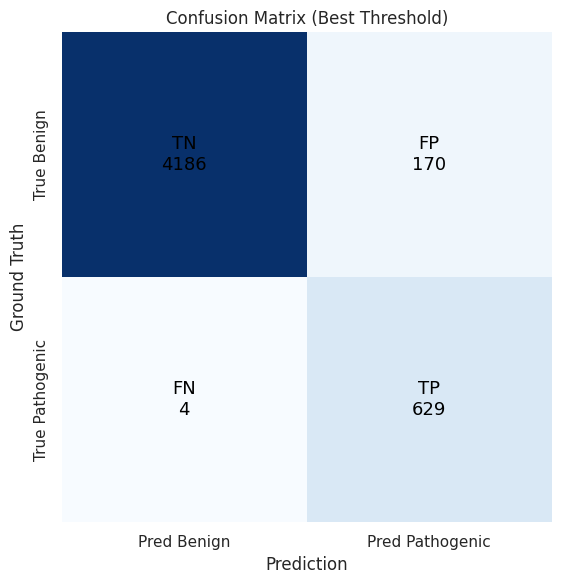

In [7]:
# Confusion Matrix with TP/TN/FP/FN annotations
cm = np.array([[tn, fp], [fn, tp]])

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=False, cmap='Blues', cbar=False, square=True, ax=ax,
            xticklabels=['Pred Benign', 'Pred Pathogenic'],
            yticklabels=['True Benign', 'True Pathogenic'])

labels = np.array([
    [f'TN\n{tn}', f'FP\n{fp}'],
    [f'FN\n{fn}', f'TP\n{tp}']
])
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.5, labels[i, j], ha='center', va='center', fontsize=13, color='black')

ax.set_title('Confusion Matrix (Best Threshold)')
ax.set_xlabel('Prediction')
ax.set_ylabel('Ground Truth')
plt.tight_layout()
plt.show()

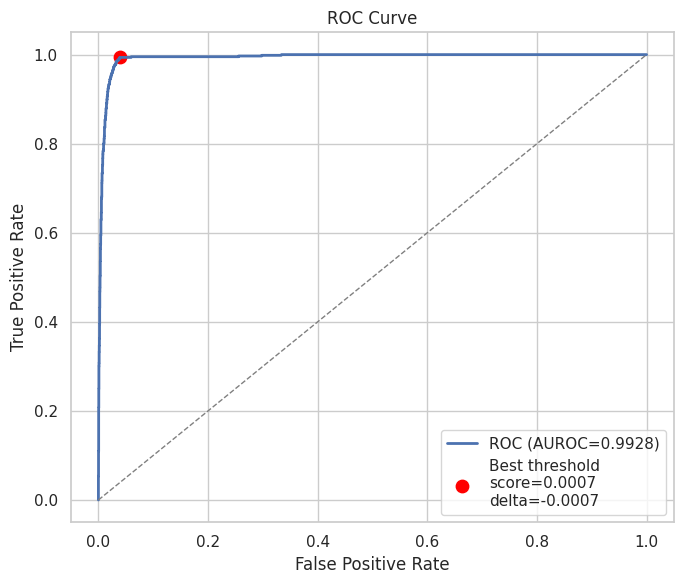

In [8]:
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC (AUROC={auroc:.4f})', linewidth=2)
plt.plot([0, 1], [0, 1], '--', color='gray', linewidth=1)
plt.scatter(fpr[best_idx], tpr[best_idx], s=80, color='red', label=(
    f'Best threshold\nscore={best_score_threshold:.4f}\n'
    f'delta={best_delta_threshold:.4f}'
))
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

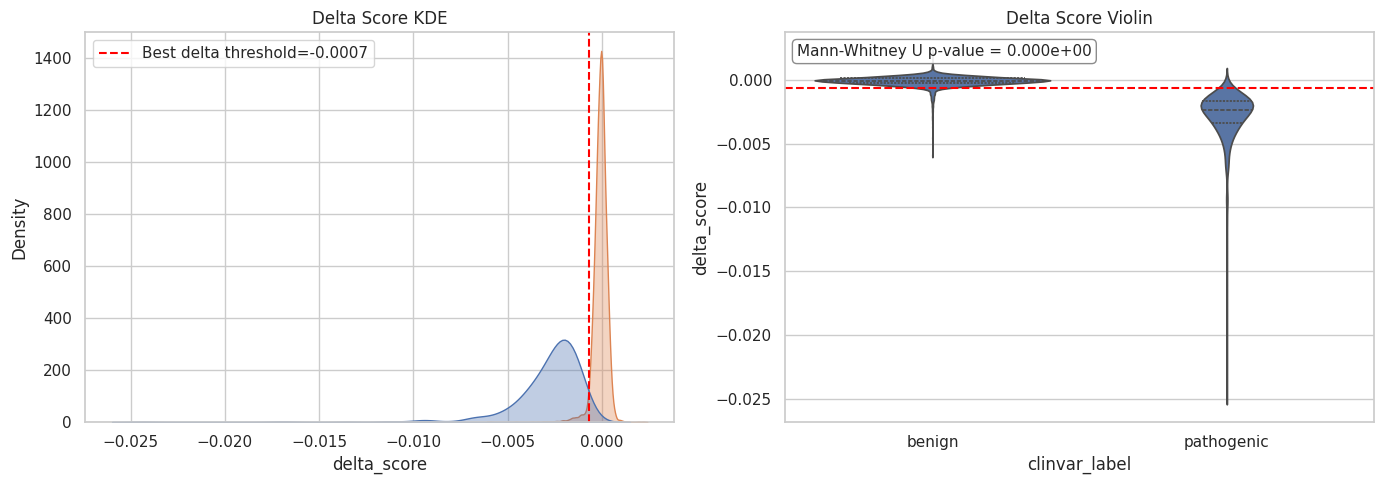

Mann-Whitney U statistic: 19830.5000
p-value: 0.000000e+00


In [9]:
# Delta score distribution: KDE + Violin + Mann-Whitney U
delta_pathogenic = eval_df.loc[eval_df['clinvar_label'] == 'pathogenic', 'delta_score']
delta_benign = eval_df.loc[eval_df['clinvar_label'] == 'benign', 'delta_score']

u_stat, p_val = mannwhitneyu(delta_pathogenic, delta_benign, alternative='two-sided')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=eval_df, x='delta_score', hue='clinvar_label', fill=True, common_norm=False, alpha=0.35, ax=axes[0])
axes[0].axvline(best_delta_threshold, color='red', linestyle='--', label=f'Best delta threshold={best_delta_threshold:.4f}')
axes[0].set_title('Delta Score KDE')
axes[0].legend()

sns.violinplot(data=eval_df, x='clinvar_label', y='delta_score', order=['benign', 'pathogenic'], ax=axes[1], inner='quartile')
axes[1].axhline(best_delta_threshold, color='red', linestyle='--')
axes[1].set_title('Delta Score Violin')
axes[1].text(0.02, 0.97, f'Mann-Whitney U p-value = {p_val:.3e}', transform=axes[1].transAxes,
             va='top', ha='left', fontsize=11,
             bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.9))

plt.tight_layout()
plt.show()

print(f'Mann-Whitney U statistic: {u_stat:.4f}')
print(f'p-value: {p_val:.6e}')

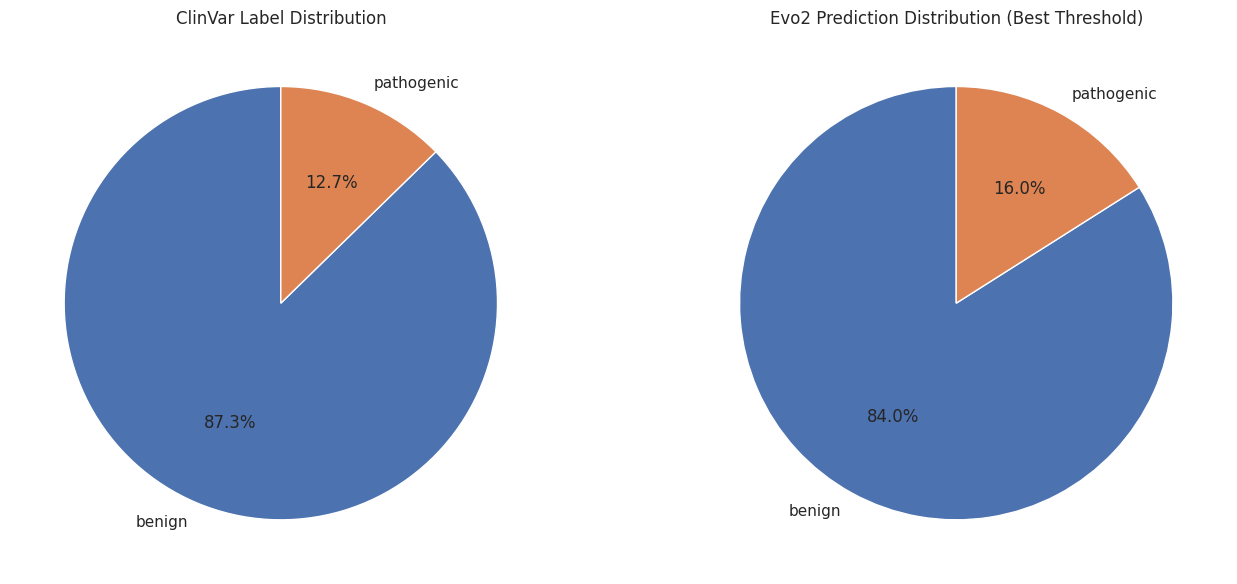

In [10]:
# Pie charts: ClinVar labels vs Evo2 predictions
full_df = result_df.copy()
full_df['pred_label_best'] = np.where((-full_df['delta_score']) >= best_score_threshold, 'pathogenic', 'benign')

clinvar_counts = full_df['clinvar_label'].value_counts().sort_index()
pred_counts = full_df['pred_label_best'].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(clinvar_counts.values, labels=clinvar_counts.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('ClinVar Label Distribution')

axes[1].pie(pred_counts.values, labels=pred_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Evo2 Prediction Distribution (Best Threshold)')

plt.tight_layout()
plt.show()

In [11]:
# Optional: save scored outputs
out_path = Path('/home/ryan910702/ttn-agent/outputs/evo2_ttn_validation_results.csv')
out_path.parent.mkdir(parents=True, exist_ok=True)
full_df.to_csv(out_path, index=False)
print(f'Saved: {out_path}')

Saved: /home/ryan910702/ttn-agent/outputs/evo2_ttn_validation_results.csv
